In [1]:
import os

# Install ultralytics if not already installed
# !pip install ultralytics

# If you are using a specific version of ultralytics, you might need to specify it:
# !pip install ultralytics==8.0.0 # Example version

# Check if ultralytics is installed, and if not, install it.
try:
    import ultralytics
    print(f"Ultralytics version: {ultralytics.__version__}")
except ImportError:
    print("Ultralytics not found. Installing...")
    !pip install ultralytics
    print("Ultralytics installed.")

Ultralytics not found. Installing...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 28.1 MB/s eta 0:00:00
Ultralytics installed.


In [4]:
from google.colab import files
import os

# Upload the image file
print("Please upload an image file from your local machine:")
uploaded = files.upload()

# Get the name of the uploaded file
if uploaded:
    uploaded_filename = list(uploaded.keys())[0]
    print(f"Uploaded file: {uploaded_filename}")
    image_path = os.path.join('/content/', uploaded_filename)
else:
    print("No file was uploaded.")
    image_path = None

Please upload an image file from your local machine:


Saving IMG_20250909_194407_994.jpg to IMG_20250909_194407_994.jpg
Uploaded file: IMG_20250909_194407_994.jpg


Running inference on /content/IMG_20250909_194407_994.jpg...

image 1/1 /content/IMG_20250909_194407_994.jpg: 640x512 1 Product_Name, 1 Wight, 288.0ms
Speed: 6.3ms preprocess, 288.0ms inference, 3.9ms postprocess per image at shape (1, 3, 640, 512)
Results saved to /content/runs/detect/predict2
Displaying inference results from /content/runs/detect/predict2/IMG_20250909_194407_994.jpg


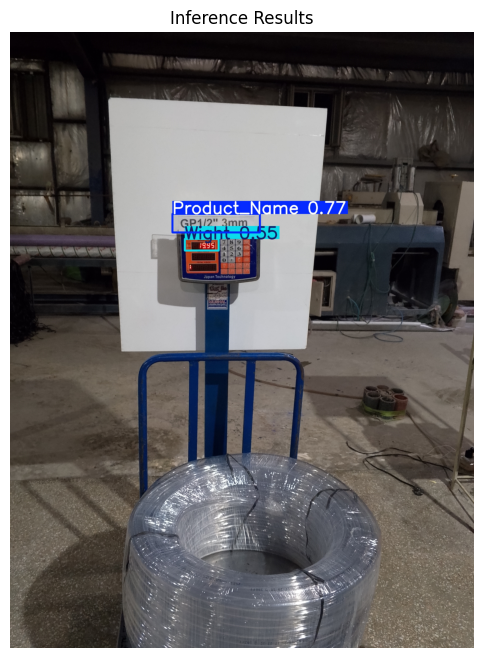

In [5]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os

# Path to the best trained model weights
# Correcting the path to the user-provided model location
model_weights_path = '/content/best.pt'

# Load the trained model
model = YOLO(model_weights_path)

if image_path and os.path.exists(image_path):
    print(f"Running inference on {image_path}...")
    # Run inference on the uploaded image
    # The 'save=True' argument saves the image with bounding boxes to a directory.
    # The results object will contain the path to the saved annotated image.
    # Adjust conf and iou thresholds as needed for your model.
    results = model.predict(source=image_path, save=True, save_txt=False, conf=0.25, iou=0.7)

    predicted_image_path = None
    if results and len(results) > 0:
        # The path to the saved annotated image is usually in results[0].save_dir
        # followed by the image name. Let's find the actual path.
        # The results object contains the path where the annotated image is saved.
        # This can be found in the `path` attribute of the `save_one_image` function within results.
        # A more robust way to get the output path is to iterate through results and then through the generated files.
        for r in results:
            # r.path contains the original image path
            # r.save_dir contains the directory where results are saved (e.g., 'runs/detect/predict')
            # We need to construct the full path to the annotated image.
            # The saved image typically has the same name as the input image.
            output_dir = r.save_dir
            base_name = os.path.basename(image_path)
            predicted_image_path = os.path.join(output_dir, base_name)
            if os.path.exists(predicted_image_path):
                break # Found the predicted image

    if predicted_image_path and os.path.exists(predicted_image_path):
        print(f"Displaying inference results from {predicted_image_path}")
        plt.figure(figsize=(10, 8))
        img = mpimg.imread(predicted_image_path)
        plt.imshow(img)
        plt.axis('off')
        plt.title('Inference Results')
        plt.show()
    else:
        print(f"Could not find the predicted image to display at {predicted_image_path}")
        print("Please check the 'runs/detect/' directory for saved images.")
else:
    print("Image path is invalid or no image was uploaded. Please upload an image first.")